In [22]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

### load data

In [41]:
df=pd.read_csv('house_price_dataset.csv').astype(int)
df.head()

,area_sqft,bedrooms,bathrooms,balconies,floors,age_years,parking_slots,furnishing,distance_city_center_km,on_highway,distance_highway_km,road_width_ft,price_lakh
0,903,1,1,1,2,22,1,1,9,0,2,30,22
1,3231,5,4,1,3,2,3,2,14,1,0,100,140
2,2825,3,2,1,2,16,2,1,11,0,7,40,59
3,2092,2,1,2,3,12,3,2,24,0,2,40,50
4,2072,2,2,2,2,29,2,2,13,1,0,60,69


In [6]:
df.shape

(1500, 13)

In [19]:
df.head()

,area_sqft,bedrooms,bathrooms,balconies,floors,age_years,parking_slots,furnishing,distance_city_center_km,on_highway,distance_highway_km,road_width_ft,price_lakh
0,903,1,1,1,2,22,1,1,9,0,2,30,22
1,3231,5,4,1,3,2,3,2,14,1,0,100,140
2,2825,3,2,1,2,16,2,1,11,0,7,40,59
3,2092,2,1,2,3,12,3,2,24,0,2,40,50
4,2072,2,2,2,2,29,2,2,13,1,0,60,69


In [21]:
df.isnull().sum()

area_sqft                  0
bedrooms                   0
bathrooms                  0
balconies                  0
floors                     0
age_years                  0
parking_slots              0
furnishing                 0
distance_city_center_km    0
on_highway                 0
distance_highway_km        0
road_width_ft              0
price_lakh                 0
dtype: int64

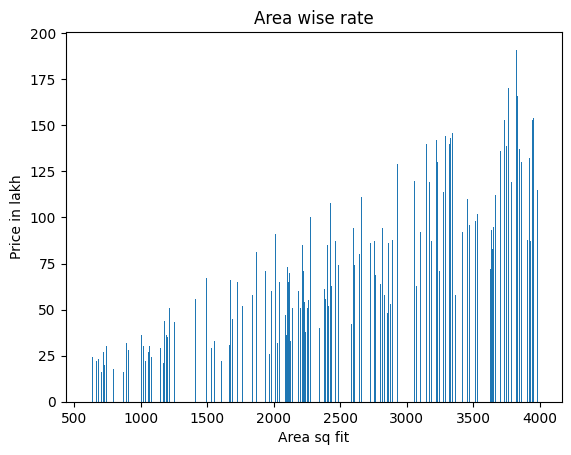

In [24]:
plt.bar(df['area_sqft'],df['price_lakh'])
plt.title('Area wise rate')
plt.xlabel('Area sq fit')
plt.ylabel('Price in lakh')
plt.show()


## Feature Scaling

In [25]:
X=df.drop(columns='price_lakh')
y=df['price_lakh']


In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [27]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaler=scaler.fit_transform(X_train)
X_test_scaler=scaler.transform(X_test)

 ### import decisiontreeregressor

In [33]:
from sklearn.tree import DecisionTreeRegressor
model=DecisionTreeRegressor(max_depth=8,min_samples_leaf=5,random_state=42)
model.fit(X_train_scaler,y_train)
pred=model.predict(X_test_scaler)
pred


array([124.42857143,  77.27272727, 128.375     ,  25.57142857,
       106.8       ,  68.44444444,  84.06666667,  84.06666667,
        68.44444444,  82.83333333,  25.85714286,  30.57142857,
        73.5       ,  58.2       , 128.375     , 106.8       ,
        87.375     ,  34.33333333,  31.81818182,  28.33333333,
       114.5       ,  59.33333333,  59.6       , 136.75      ,
        80.875     , 129.33333333,  21.44444444,  83.        ,
        75.22222222,  98.875     , 118.88888889,  94.875     ,
        61.75      ,  94.875     ,  39.07142857, 129.33333333,
        88.        ,  22.125     ,  49.11111111,  49.63636364,
        64.22222222,  58.2       ,  84.66666667, 129.33333333,
        85.55555556, 171.28571429,  51.        ,  31.81818182,
       122.11111111,  59.33333333,  55.        ,  30.92307692,
       122.11111111,  69.66666667,  77.27272727, 157.375     ,
        67.        ,  59.33333333, 110.875     ,  64.22222222,
        29.375     ,  99.57142857,  58.2       ,  61.75

### Check model accuracy

In [38]:
from sklearn.metrics import r2_score,mean_absolute_error
r2=("R2:",round(r2_score(y_test,pred),3))
print(r2)
print('MAE:',round(mean_absolute_error(y_test,pred),2),"lakh")

('R2:', 0.912)
MAE: 7.93 lakh


In [40]:
import joblib
joblib.dump(model,'house_model.pkl')
joblib.dump(scaler,'scaler.pkl')
joblib.dump(X.columns.to_list(),'columns.pkl')

['columns.pkl']